Dataset Loading

In [1]:
import kagglehub
path = kagglehub.dataset_download("mirichoi0218/insurance")

100%|██████████| 16.0k/16.0k [00:00<00:00, 1.72MB/s]

Extracting files...


In [2]:
import pandas as pd
import os
x=os.path.join(path,"insurance.csv")
df=pd.read_csv(x)

In [3]:
import pandas as pd

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Shape: (1338, 7)
Rows: 1338
Columns: 7


In [5]:
print(df.columns.tolist())

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Data Cleaning & Preprocessing

Missing values

In [8]:
print(df.isnull().sum())


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Duplicates

In [9]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 1


In [10]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Duplicate remove

In [11]:
df = df.drop_duplicates().reset_index(drop=True)


In [12]:
df.shape

(1337, 7)

Data types check

In [13]:
print(df.dtypes)


age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


Before encoding

In [14]:
print("BEFORE ENCODING")
df.head()

BEFORE ENCODING


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Encoding

In [15]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
le = LabelEncoder()



In [16]:
df_encoded['sex'] = le.fit_transform(df_encoded['sex'])
print('sex:', list(le.classes_))


sex: ['female', 'male']


In [17]:
df_encoded['smoker'] = le.fit_transform(df_encoded['smoker'])
print('smoker:', list(le.classes_))


smoker: ['no', 'yes']


In [18]:
df_encoded['region'] = le.fit_transform(df_encoded['region'])
print('region:', list(le.classes_))


region: ['northeast', 'northwest', 'southeast', 'southwest']


Final dataset

In [19]:
df_encoded.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520


In [20]:
df_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   int64  
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   int64  
 5   region    1337 non-null   int64  
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(5)
memory usage: 73.2 KB


In [21]:
df_encoded.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Exploratory Data Analysis

Import Libraries

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

hist plot


Graph 1, Charges ka distribution

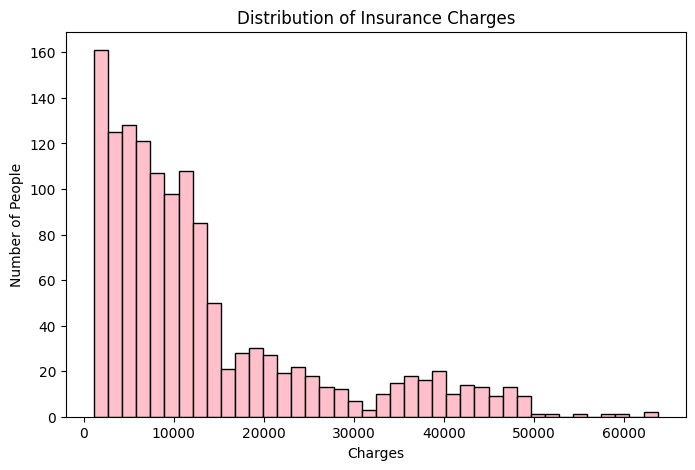

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(df['charges'], bins=40, color='pink', edgecolor='black')
plt.title('Distribution of Insurance Charges')
plt.xlabel('Charges')
plt.ylabel('Number of People')
plt.show()

boxplot

Graph 2, Smoker vs Charges

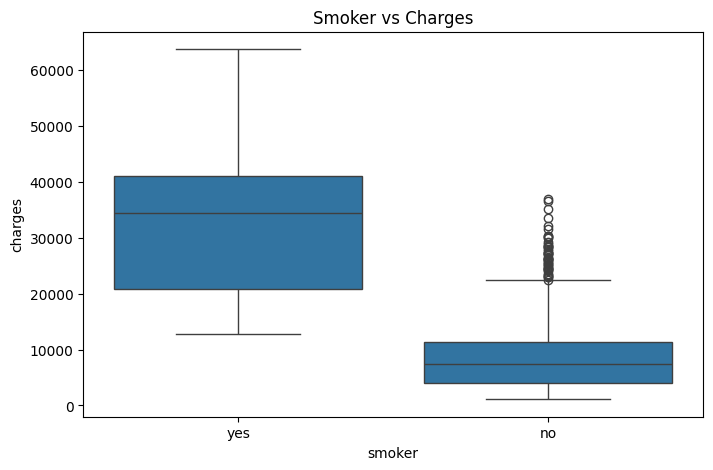

In [24]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title('Smoker vs Charges')
plt.show()



scatterplot

Graph 3, Age vs Charges

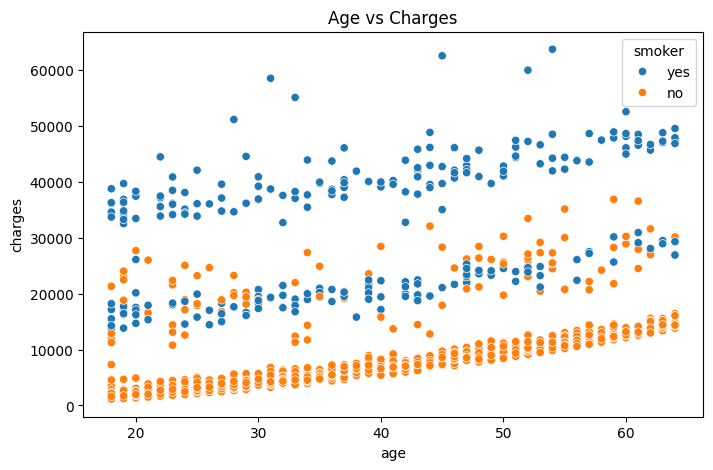

In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df)
plt.title('Age vs Charges')
plt.show()

scatterplot

Graph 4, BMI vs Charges

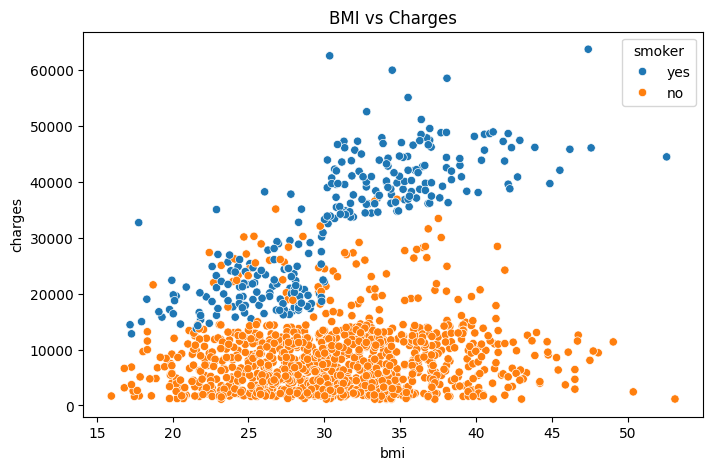

In [26]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)
plt.title('BMI vs Charges')
plt.show()

Correlation analysis

In [27]:
corr = df_encoded.corr()
print(corr['charges'].sort_values(ascending=False))



charges     1.000000
smoker      0.787234
age         0.298308
bmi         0.198401
children    0.067389
sex         0.058044
region     -0.006547
Name: charges, dtype: float64


heatmap

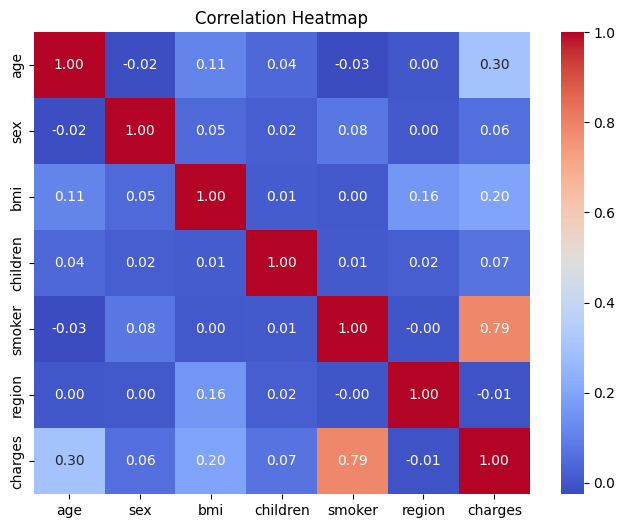

In [28]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Train Linear Regression Model

X aur y alag karo

In [29]:
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']



In [30]:
print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (1337, 6)
y shape: (1337,)


,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,3
1,18,1,33.770,1,0,2
2,28,1,33.000,3,0,2
3,33,1,22.705,0,0,1
4,32,1,28.880,0,0,1


Train/Test split

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [32]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1069, 6)
X_test : (268, 6)
y_train: (1069,)
y_test : (268,)


Model train karo

In [33]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training complete")

Model training complete


Model ne kya seekha

In [34]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred.round(2)
})
result.head(10)

,Actual,Predicted
0,8688.85885,8080.45
1,5708.86700,5592.87
2,11436.73815,14378.30
3,38746.35510,31731.82
4,4463.20510,9158.36
5,9304.70190,13361.01
6,38511.62830,30257.66
7,2150.46900,1308.65
8,7345.72660,10849.43
9,10264.44210,11375.55


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [36]:
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
print("MAE  :", round(mae, 2))


MAE  : 4182.35


In [37]:
mse = mean_squared_error(y_test, y_pred)
print("MSE  :", round(mse, 2))


MSE  : 35493102.61


In [38]:
rmse = np.sqrt(mse)
print("RMSE :", round(rmse, 2))


RMSE : 5957.61


In [39]:
r2 = r2_score(y_test, y_pred)

print("R2   :", round(r2, 4))

R2   : 0.8068


In [40]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred.round(2)
})
comparison['Difference'] = (comparison['Actual'] - comparison['Predicted']).round(2)
comparison.head(10)

,Actual,Predicted,Difference
0,8688.85885,8080.45,608.41
1,5708.86700,5592.87,116.00
2,11436.73815,14378.30,-2941.56
3,38746.35510,31731.82,7014.54
4,4463.20510,9158.36,-4695.15
5,9304.70190,13361.01,-4056.31
6,38511.62830,30257.66,8253.97
7,2150.46900,1308.65,841.82
8,7345.72660,10849.43,-3503.70
9,10264.44210,11375.55,-1111.11


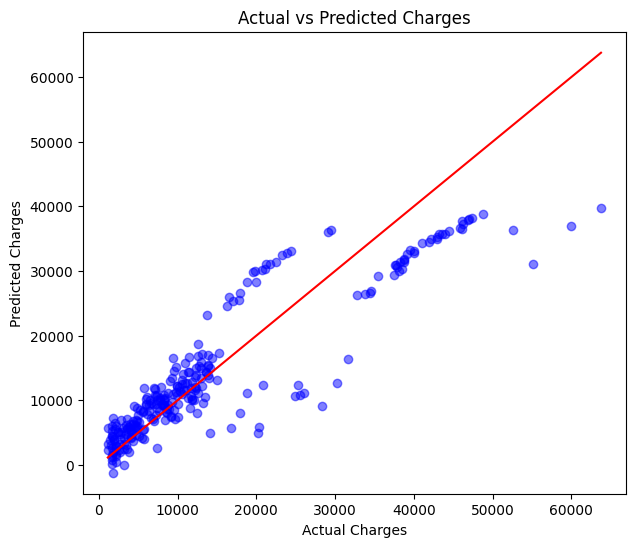

In [41]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
plt.show()